# Housing prices, electoral democracy and LGBTQ legal equality across U.S. states

Exploratory, descriptive analysis. Nothing here estimates a causal effect.

Three concepts are kept separate throughout:

* **Electoral democracy:** Berkeley State Democracy Index (SDI) 2.0, `democracy_mcmc`.
* **LGBTQ legal rights and protections:** the MAP overall policy tally and the HRC State Equality Index category. Neither is a comprehensive human rights index.
* **Housing prices and affordability:** the Zillow Home Value Index (ZHVI), with ZHVI / median household income as an affordability *proxy*.

The pre-specified models are in `docs/analysis_plan.md`; model labels (C1, P1, S1, ...) match it.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display
from hdl import PROC, FIG
from hdl.analysis import run_all, load

pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
print("pandas", pd.__version__)

pandas 3.1.1


## 1. Data and merge validation

`scripts/02_build.py` built the panel and raised on any failed check: duplicate keys, unmatched states, unexpected year ranges, or broken BEA identities. The merge log and coverage are shown below.

In [2]:
display(pd.read_csv(PROC / "merge_log.csv"))
panel, cs = load()
cov = panel.groupby("year")[["sdi", "zhvi", "rpp_all", "eds", "covi", "map_overall", "hrc_category", "acs_value"]].count()
cov

,source,rows_in_source,rows_in_2000_2024,rows_matched,unmatched_in_window,years
0,sdi,1200,1200,1200,0,2000-2023
1,rhodes,350,350,350,0,2000-2022
2,covi,450,400,400,0,1996-2024
3,party,1150,1150,1150,0,2000-2022
4,zhvi,1280,1230,1230,0,2000-2025
5,fhfa,2550,1250,1250,0,1975-2025
6,acs,100,100,100,0,2022-2023
7,rpp,850,850,850,0,2008-2024
8,irpd,850,850,850,0,2008-2024
9,real_income,850,850,850,0,2008-2024


,sdi,zhvi,rpp_all,eds,covi,map_overall,hrc_category,acs_value
year,,,,,,,,
2000,50,46,0,50,50,0,0,0
2001,50,46,0,0,0,0,0,0
2002,50,46,0,0,0,0,0,0
2003,50,48,0,0,0,0,0,0
2004,50,48,0,50,50,0,0,0
2005,50,49,0,0,0,0,0,0
2006,50,49,0,0,0,0,0,0
2007,50,49,0,0,0,0,0,0
2008,50,49,50,50,50,0,0,0


ZHVI has gaps before 2009 (North Dakota, Montana, New Mexico and Wyoming). Those state-years are missing; nothing is interpolated. SDI 2.0 ends in 2023, so the 2024 SDI values are missing by design.

In [3]:
res = run_all()  # writes output/tables and output/figures

## 2. The 2023 cross-section

In [4]:
res['desc']

,variable,n,mean,sd,min,median,max
0,SDI 2.0 (democracy_mcmc),50,-0.056,1.067,-2.895,0.175,1.659
1,SDI 2.0 additive,50,0.933,1.177,-1.654,1.103,2.830
2,ZHVI ($),50,354207.140,138570.353,158247.000,325816.000,827921.000
3,ACS median owner-occupied value ($),50,344548.000,140070.175,163700.000,309650.000,846400.000
4,ACS median household income ($),50,76976.480,12262.197,54203.000,74631.500,99858.000
5,ZHVI / median HH income,50,4.496,1.214,2.828,4.241,8.686
6,MAP overall policy tally,50,16.360,17.705,-11.500,11.625,42.750
7,RPP all items,50,96.709,7.023,86.792,96.105,112.195
8,RPP housing rents,50,91.037,24.723,54.923,84.039,157.831
9,RPP goods,50,98.334,3.959,93.009,97.350,110.346


In [5]:
res['corr']

,pair,n,spearman,spearman_p,pearson,pearson_ci_low,pearson_ci_high,pearson_p
0,SDI vs ZHVI ($),50,0.531,7.285e-05,0.475,0.227,0.666,4.843e-04
1,SDI vs log ZHVI,50,0.531,7.285e-05,0.498,0.255,0.682,2.309e-04
2,SDI additive vs log ZHVI,50,0.542,4.728e-05,0.534,0.300,0.707,6.595e-05
3,SDI vs log ACS median value,50,0.530,7.630e-05,0.505,0.264,0.687,1.835e-04
4,SDI vs log(ZHVI / HH income),50,0.385,5.783e-03,0.366,0.098,0.585,8.875e-03
5,SDI vs log HH income,50,0.590,6.516e-06,0.569,0.345,0.731,1.643e-05
6,SDI vs BA share,50,0.624,1.306e-06,0.580,0.359,0.739,1.027e-05
7,SDI vs urban share,50,0.397,4.302e-03,0.327,0.054,0.555,2.032e-02
8,MAP tally vs log ZHVI,50,0.605,3.313e-06,0.612,0.402,0.761,2.363e-06
9,MAP tally vs log(ZHVI / income),50,0.414,2.826e-03,0.447,0.193,0.645,1.124e-03


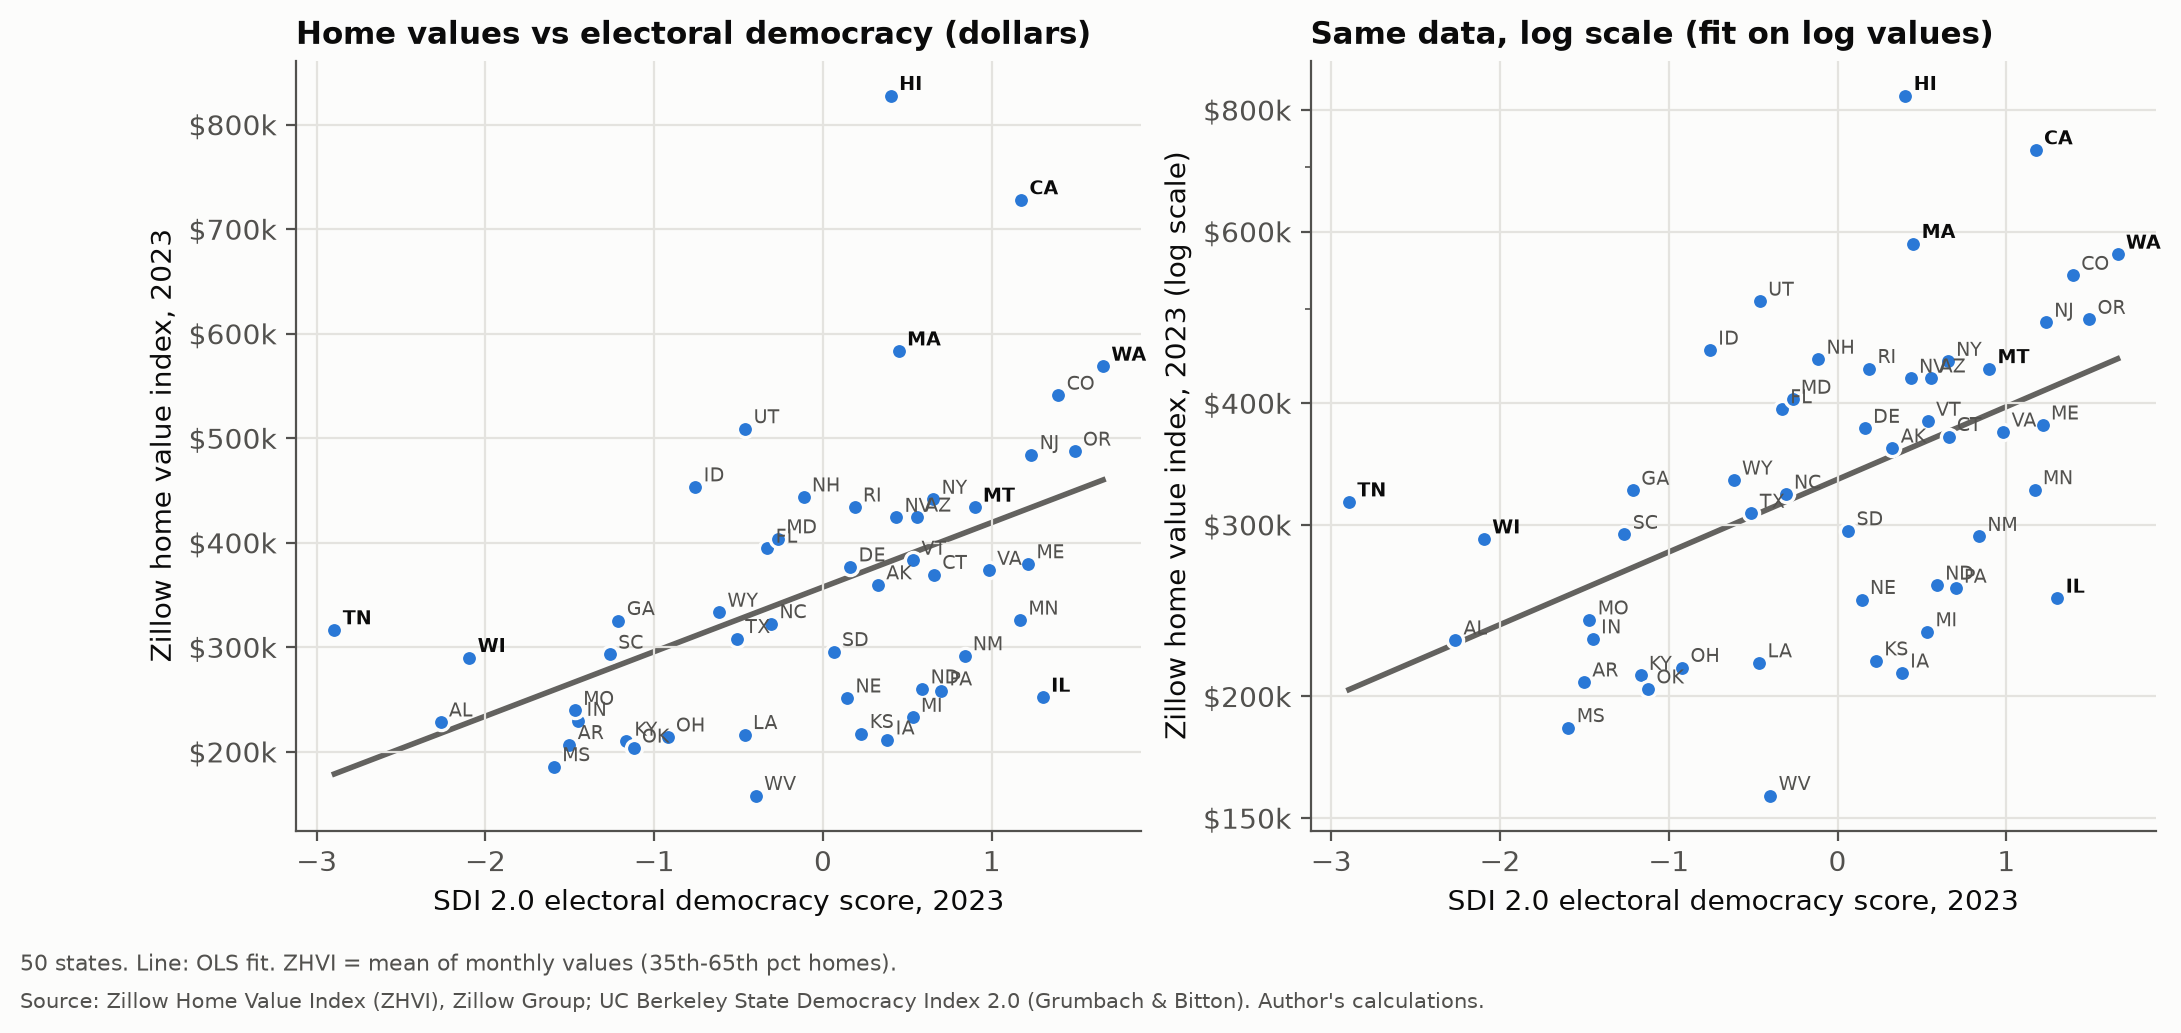

In [6]:
display(Image(str(FIG / 'f01_sdi_vs_home_values_2023.png')))

States with higher SDI scores have higher home values. The rank correlation is about 0.53. The scatter also shows wide dispersion: Tennessee (lowest SDI) has higher values than Illinois (one of the highest), and Hawaii, California and Massachusetts sit far above the line.

In [7]:
res['cross']['table'][['model','term','coef','ci_low','ci_high','pct_per_sd','n','r2','conley1000_se','resid_morans_i','morans_p']]

,model,term,coef,ci_low,ci_high,pct_per_sd,n,r2,conley1000_se,resid_morans_i,morans_p
0,C1 bivariate,D,0.183,0.093,0.273,20.108,50,0.248,0.041,0.393,1.000e-04
1,"C2 + income, education, urban",D,0.022,-0.061,0.106,2.270,50,0.693,0.042,0.449,1.000e-04
2,C3 C2 + region,D,-0.035,-0.089,0.018,-3.479,50,0.877,0.027,0.034,5.030e-01
3,C4 C2 + party control (2022),D,-0.014,-0.111,0.082,-1.435,49,0.737,0.047,0.389,1.000e-04
4,E1 MAP bivariate,MAP,0.225,0.146,0.304,25.223,50,0.374,0.037,0.419,1.000e-04
5,E2 MAP + controls,MAP,0.035,-0.059,0.129,3.545,50,0.695,0.050,0.463,1.000e-04
6,E3 SDI + MAP + controls (SDI),D,0.008,-0.109,0.126,0.842,50,0.695,0.052,0.459,1.000e-04
7,E3 SDI + MAP + controls (MAP),MAP,0.029,-0.103,0.162,2.967,50,0.695,0.063,0.459,1.000e-04
8,A1 log(ZHVI/income) bivariate,D,0.092,0.026,0.159,9.688,50,0.134,0.031,0.512,1.000e-04
9,"A1 log(ZHVI/income) + educ, urban",D,0.034,-0.047,0.115,3.462,50,0.267,0.041,0.563,1.000e-04


**Reading C1 vs C2.** The bivariate coefficient (C1: about +20% home value per SD of SDI) falls to about +2% once median household income, the college share and the urban share are added (C2). The C2 interval comfortably includes zero. These controls are not neutral: education and income are themselves part of the sorting story. The original observation is consistent with democracy scores and home values *both* lining up with richer, more educated, more urban states. On its own it does not point to anything specific to democracy.

Residuals are spatially autocorrelated (Moran's I about 0.4). Conley spatial-HAC standard errors are similar to the HC3 ones, and regional indicators remove most of the residual spatial pattern.

In [8]:
res['sens']

,spec,coef,se,ci_low,ci_high,p,pct_per_sd,n,r2,note
0,Main C1,0.183,0.046,0.093,0.273,6.425e-05,20.108,50,0.248,
1,Main C2,0.022,0.043,-0.061,0.106,5.993e-01,2.270,50,0.693,
2,S1 additive SDI (C1),0.196,0.040,0.118,0.275,9.285e-07,21.678,50,0.285,
3,S1 additive SDI (C2),0.018,0.042,-0.064,0.100,6.718e-01,1.792,50,0.692,
4,S2 ACS median value (C1),0.186,0.047,0.095,0.278,6.316e-05,20.492,50,0.255,
5,S2 ACS median value (C2),0.022,0.038,-0.054,0.097,5.708e-01,2.203,50,0.747,
6,S3 ZHVI in $000 (C1),65.883,16.430,33.681,98.085,6.072e-05,NaN,50,0.226,coefficient in $000 per SD
7,S3 ZHVI in $000 (C2),11.845,14.844,-17.249,40.939,4.249e-01,NaN,50,0.634,coefficient in $000 per SD
8,"S4 drop AK, HI (C1)",0.178,0.046,0.087,0.270,1.230e-04,19.541,48,0.260,
9,"S4 drop AK, HI (C2)",0.026,0.044,-0.060,0.111,5.536e-01,2.619,48,0.690,


**Sensitivity.** The C1/C2 pattern holds with:
* the additive SDI;
* ACS self-reported values;
* dollar levels;
* Alaska and Hawaii dropped;
* population weights, which change the estimand to the person-weighted association;
* region or party-control controls;
* SDI posterior draws.

Two alternative measures differ. Rhodes's Electoral Democracy Score (2022) and the Cost of Voting Index (2022, a narrower voting-access measure) keep a modest adjusted association of about 10% per SD. These indexes share many inputs with SDI, so they are sensitivity checks, not independent replications. The difference is a measurement question worth flagging, not a resolved finding.

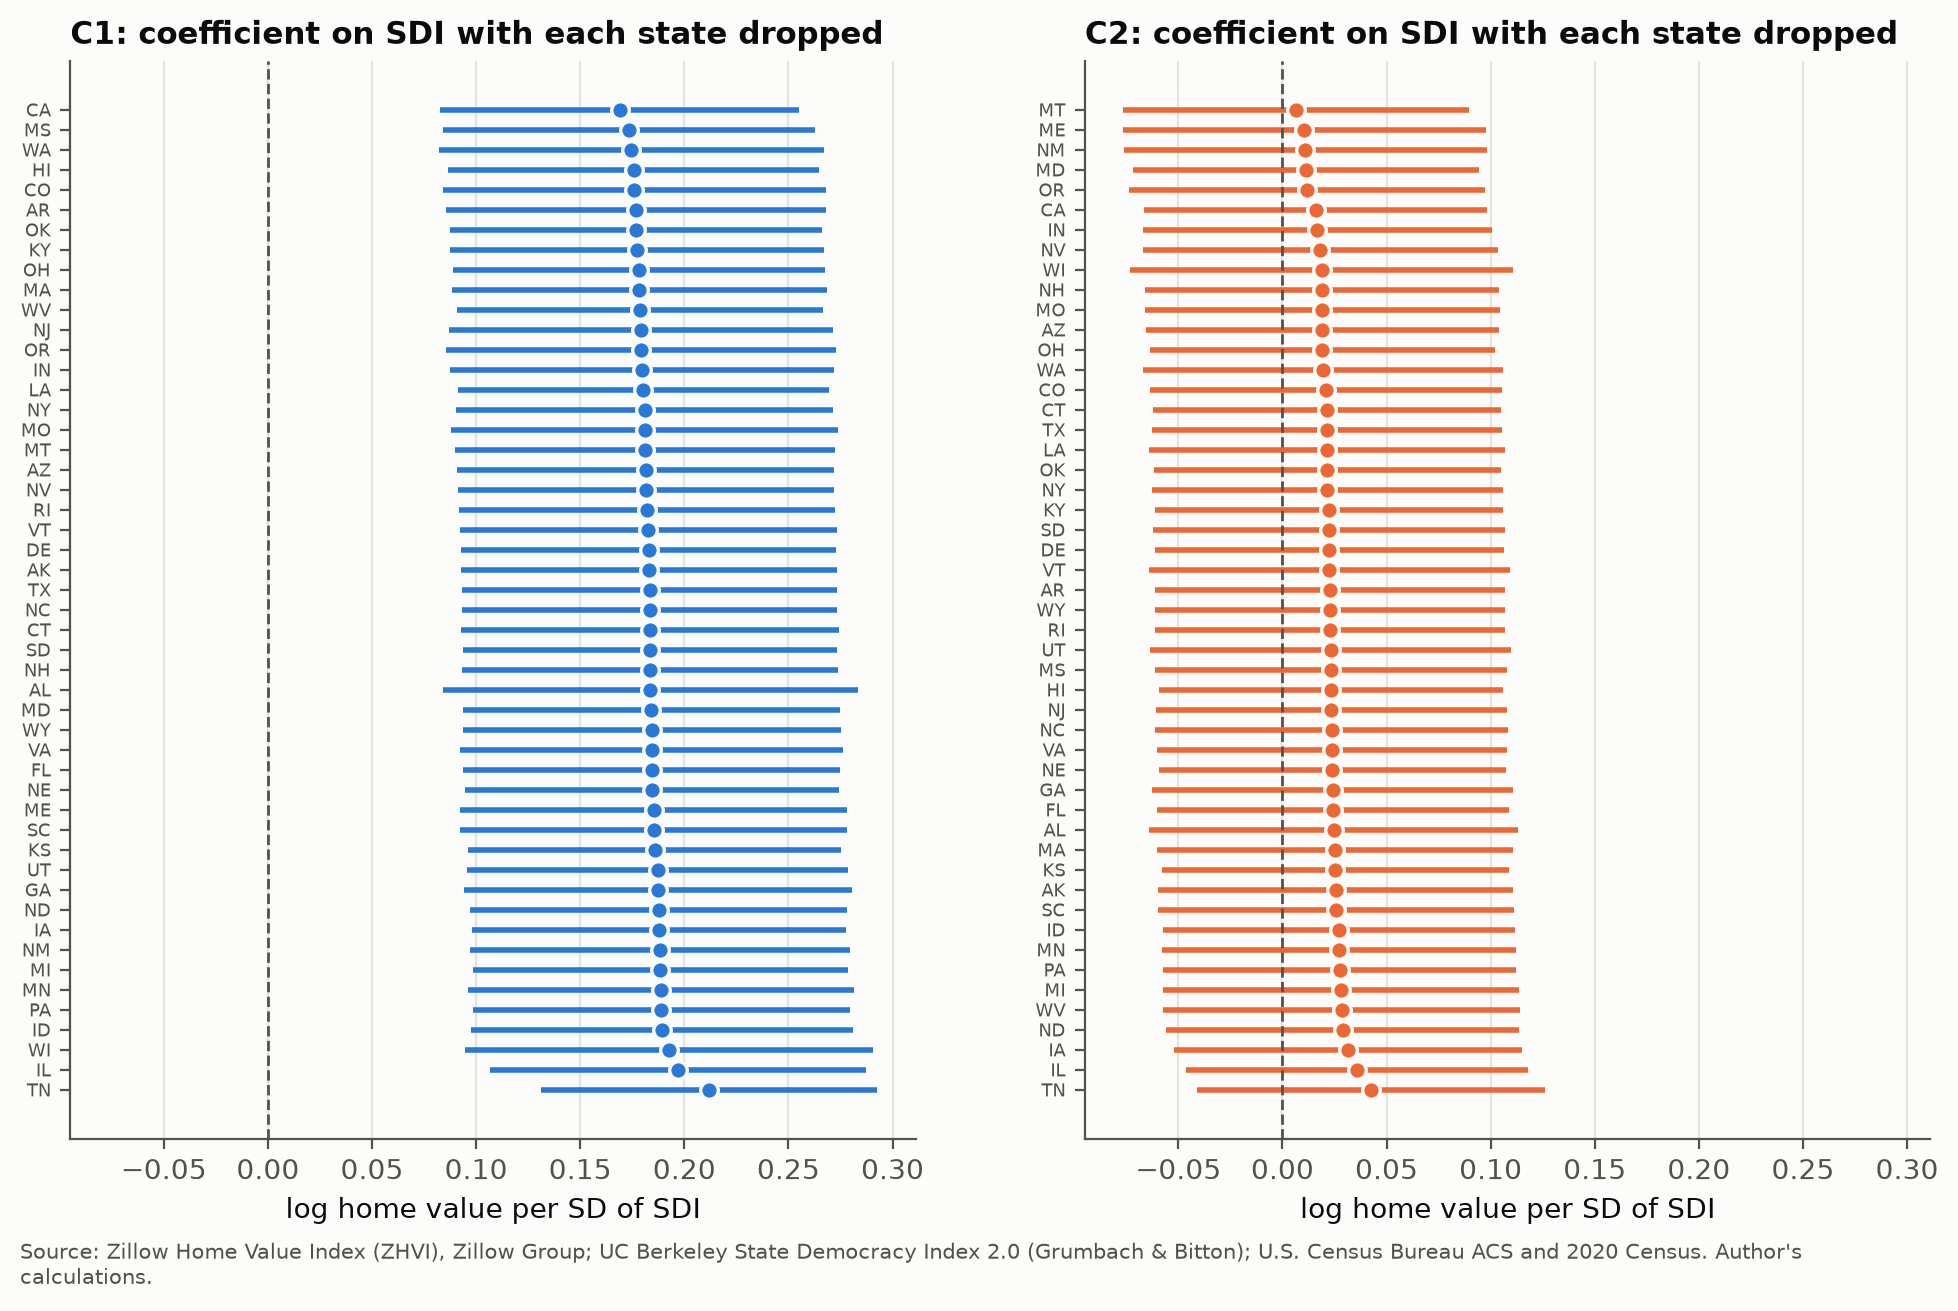

,model,min_coef,max_coef,dropped_at_min,n_ci_excluding_zero
0,C1,0.169,0.212,CA,50
1,C2,0.007,0.043,MT,0


In [9]:
display(Image(str(FIG / 'f04_leave_one_out.png')))
res['influence']['summary']

## 3. Between vs within states

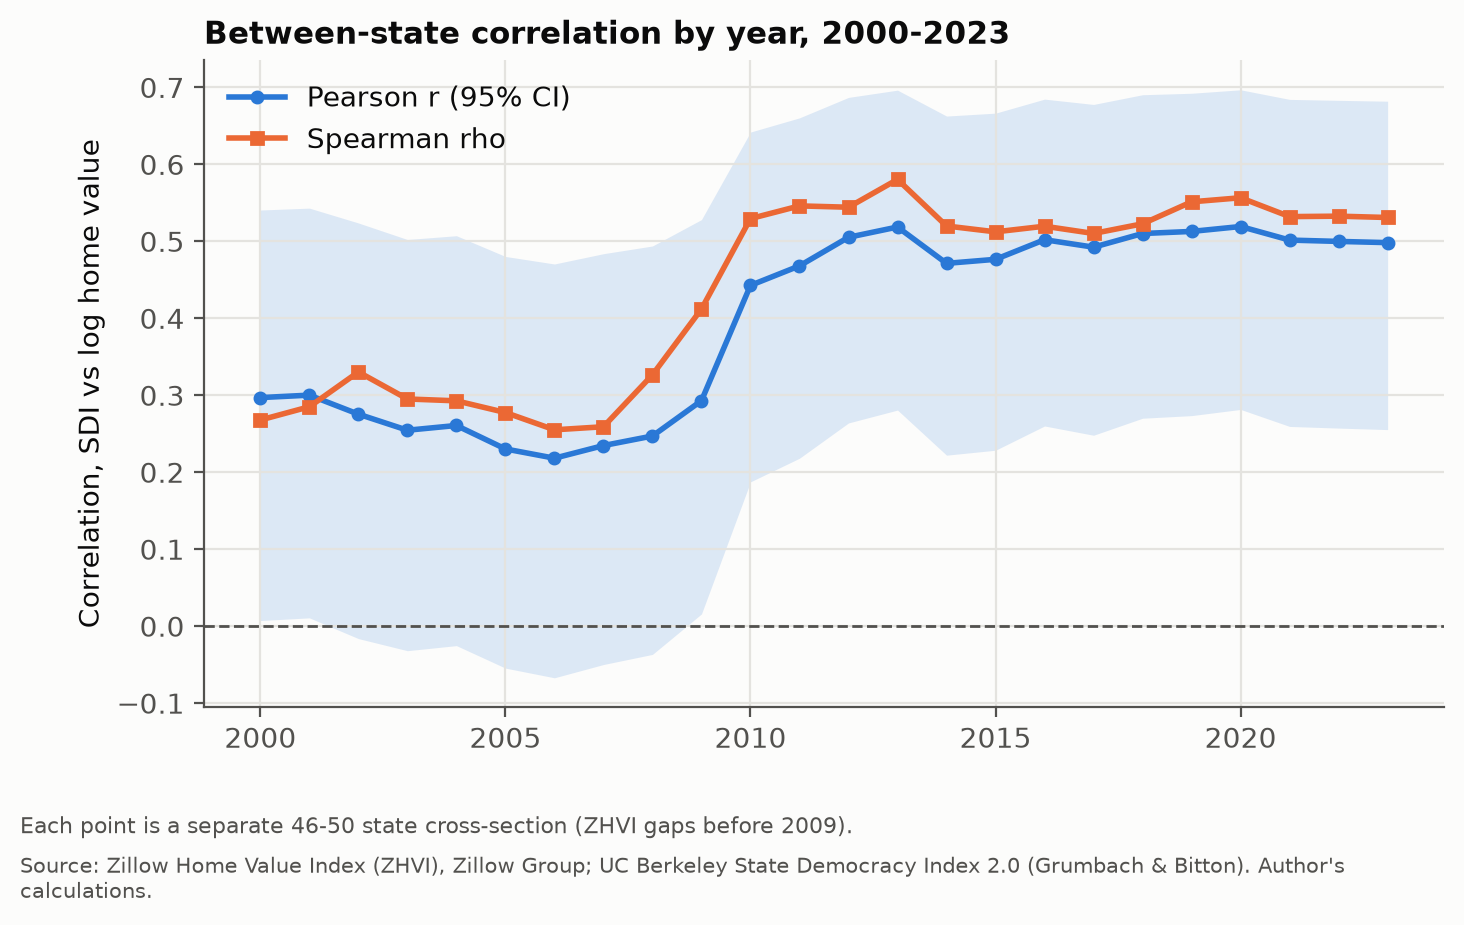

,variable,total_var,within_state_share,two_way_residual_share
0,sdi,0.873,0.310,0.277
1,log_zhvi_real,0.134,0.204,0.067
2,mean |annual change in SDI|: odd years / even ...,NaN,0.024,0.239


In [10]:
display(Image(str(FIG / 'f02_annual_correlations.png')))
res['vardecomp']

The between-state correlation rose from about 0.25-0.30 in the 2000s to about 0.5 from 2010 onward, as SDI scores spread out. About 31% of SDI's variance is within states. SDI changes are concentrated in even (election) years: the mean absolute change is about 0.24 in even years and about 0.02 in odd years. The annual panel therefore carries far fewer independent changes than its 24 rows suggest.

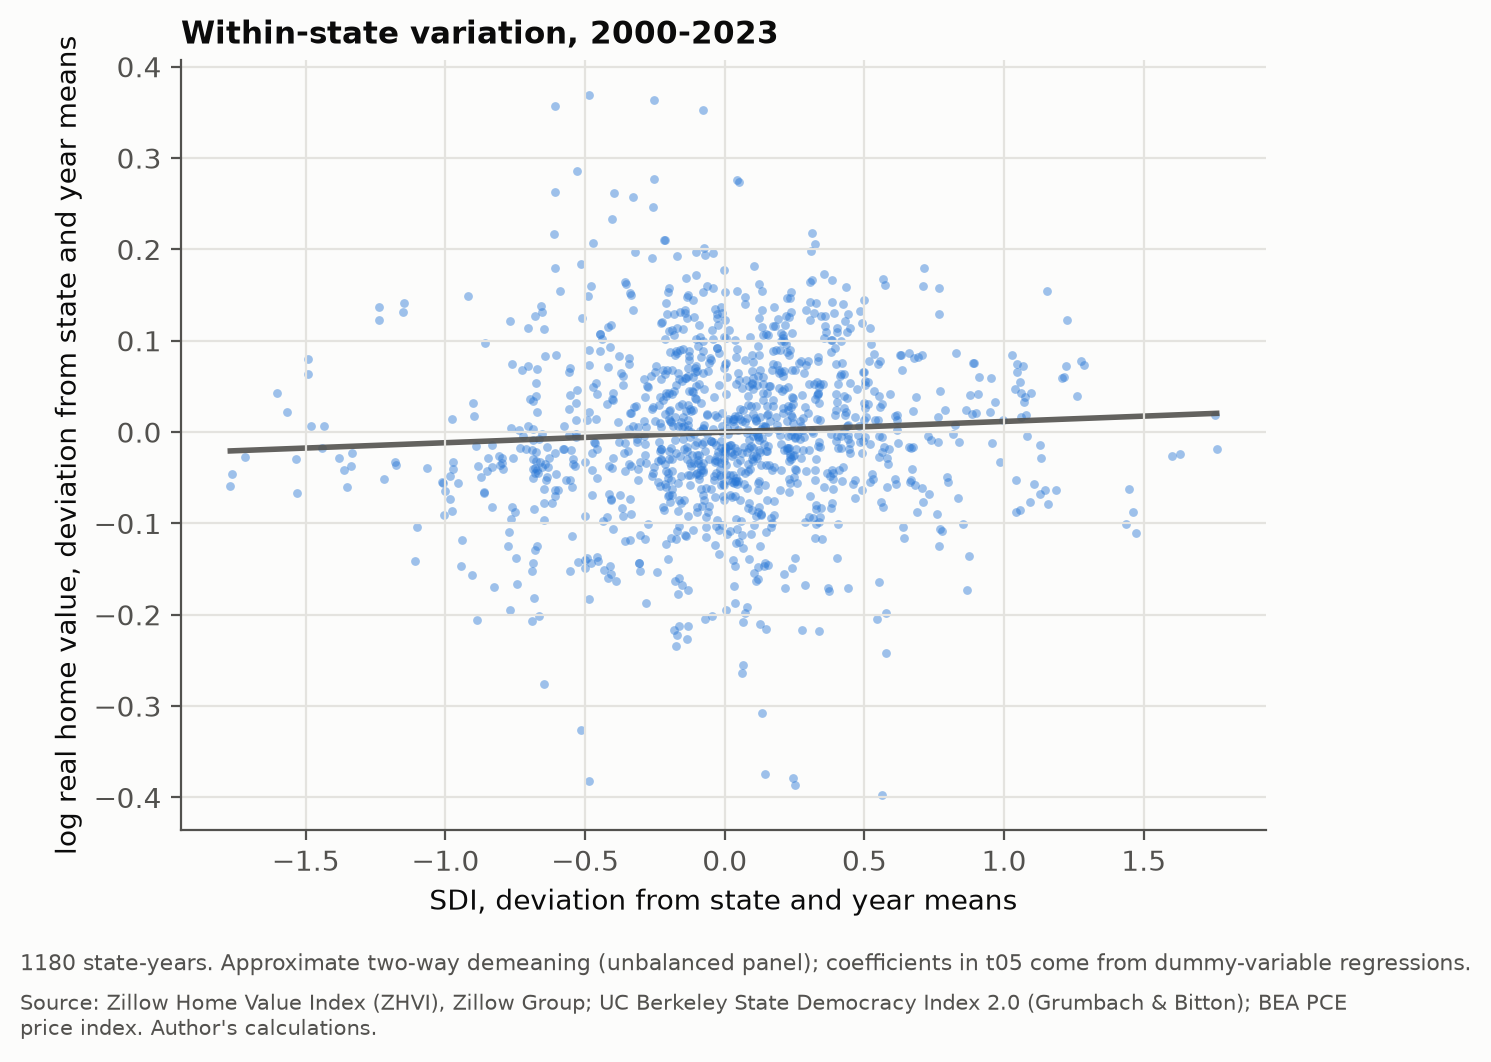

,model,term,coef,se,ci_low,ci_high,p,n,r2,se_type,pct_per_unit,n_states
0,"P1a TWFE, no controls",sdi,0.012,0.012,-0.012,0.036,0.330,1180,0.933,cluster(state),1.193,50.0
1,P1b TWFE + log real PCPI,sdi,0.009,0.010,-0.010,0.029,0.347,1180,0.953,cluster(state),0.941,50.0
2,P1b Driscoll-Kraay(3),sdi,0.009,0.015,-0.021,0.039,0.540,1180,0.953,Driscoll-Kraay(3),0.941,50.0
3,P1c TWFE 2008-2023 + log real PCPI,sdi,0.018,0.010,-0.001,0.038,0.070,799,0.977,cluster(state),1.817,NaN
4,P2 Mundlak (CRE),within (x),0.008,0.010,-0.011,0.027,0.405,1180,0.559,cluster(state),0.797,NaN
5,P2 Mundlak (CRE),between (x + xbar),0.110,0.038,0.035,0.185,0.004,1180,0.559,cluster(state),11.651,NaN
6,P3 long diff 2000-2023,dsdi,0.027,0.028,-0.028,0.083,0.337,46,0.021,HC3,2.769,NaN
7,P3 long diff 2000-2023 + d log PCPI,dsdi,0.041,0.026,-0.009,0.091,0.112,46,0.133,HC3,4.159,NaN
8,P3 long diff 2008-2023,dsdi,-0.012,0.023,-0.056,0.033,0.605,49,0.005,HC3,-1.158,NaN
9,P3 long diff 2008-2023 + d log PCPI,dsdi,-0.026,0.016,-0.059,0.006,0.107,49,0.575,HC3,-2.609,NaN


In [11]:
display(Image(str(FIG / 'f03_within_state.png')))
res['panel']['table']

**Within states** (two-way FE, state-clustered SEs), a one-unit rise in SDI goes with roughly 1% higher real home values. The interval runs from about -1% to +4%. Driscoll-Kraay standard errors and long differences agree, and the 2008-2023 long difference is slightly negative. **Between states** (Mundlak), the association is about +12% per unit. The relationship is mainly a between-state pattern. Slow-moving institutions and few effective within-state changes mean the within estimate is imprecise, not a demonstrated zero.

In [12]:
res['appreciation']

,model,term,coef,se,ci_low,ci_high,p,n,r2,se_type,mean_appreciation_log
0,H1 real appreciation 2000-2023 ~ initial SDI (z),sdi0_z,0.066,0.026,0.014,0.118,0.013,50,0.133,HC3,0.495
1,H1 real appreciation 2000-2023 ~ SDI change,dsdi,0.016,0.030,-0.043,0.076,0.597,50,0.007,HC3,0.495
2,H1 real appreciation 2008-2023 ~ initial SDI (z),sdi0_z,-0.013,0.017,-0.046,0.020,0.436,50,0.009,HC3,0.248
3,H1 real appreciation 2008-2023 ~ SDI change,dsdi,-0.006,0.022,-0.049,0.037,0.783,50,0.002,HC3,0.248


FHFA repeat-sales indexes are used only for appreciation, never for cross-state levels. States with higher SDI in 2000 appreciated more over 2000-2023, but not over 2008-2023. SDI *changes* are unrelated to appreciation in both windows.

## 4. Affordability proxy

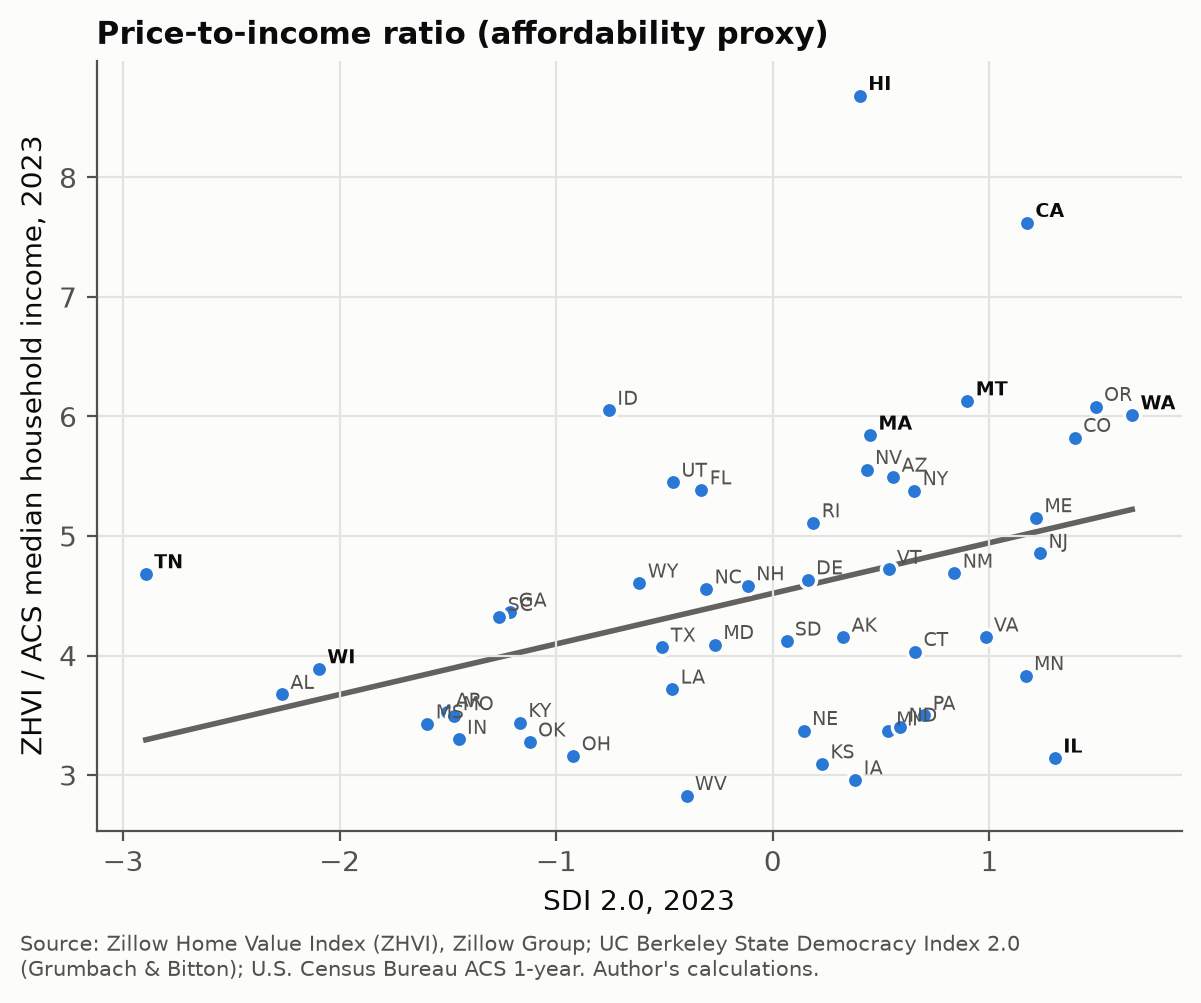

In [13]:
display(Image(str(FIG / 'f08_price_to_income.png')))

Price-to-income ratios rise with SDI too, more weakly (r about 0.37). The association disappears with education and urban controls (model A1 in the table above). This ratio ignores rents, interest rates, taxes and insurance, so it is a proxy only.

## 5. Broader price levels (BEA Regional Price Parities)

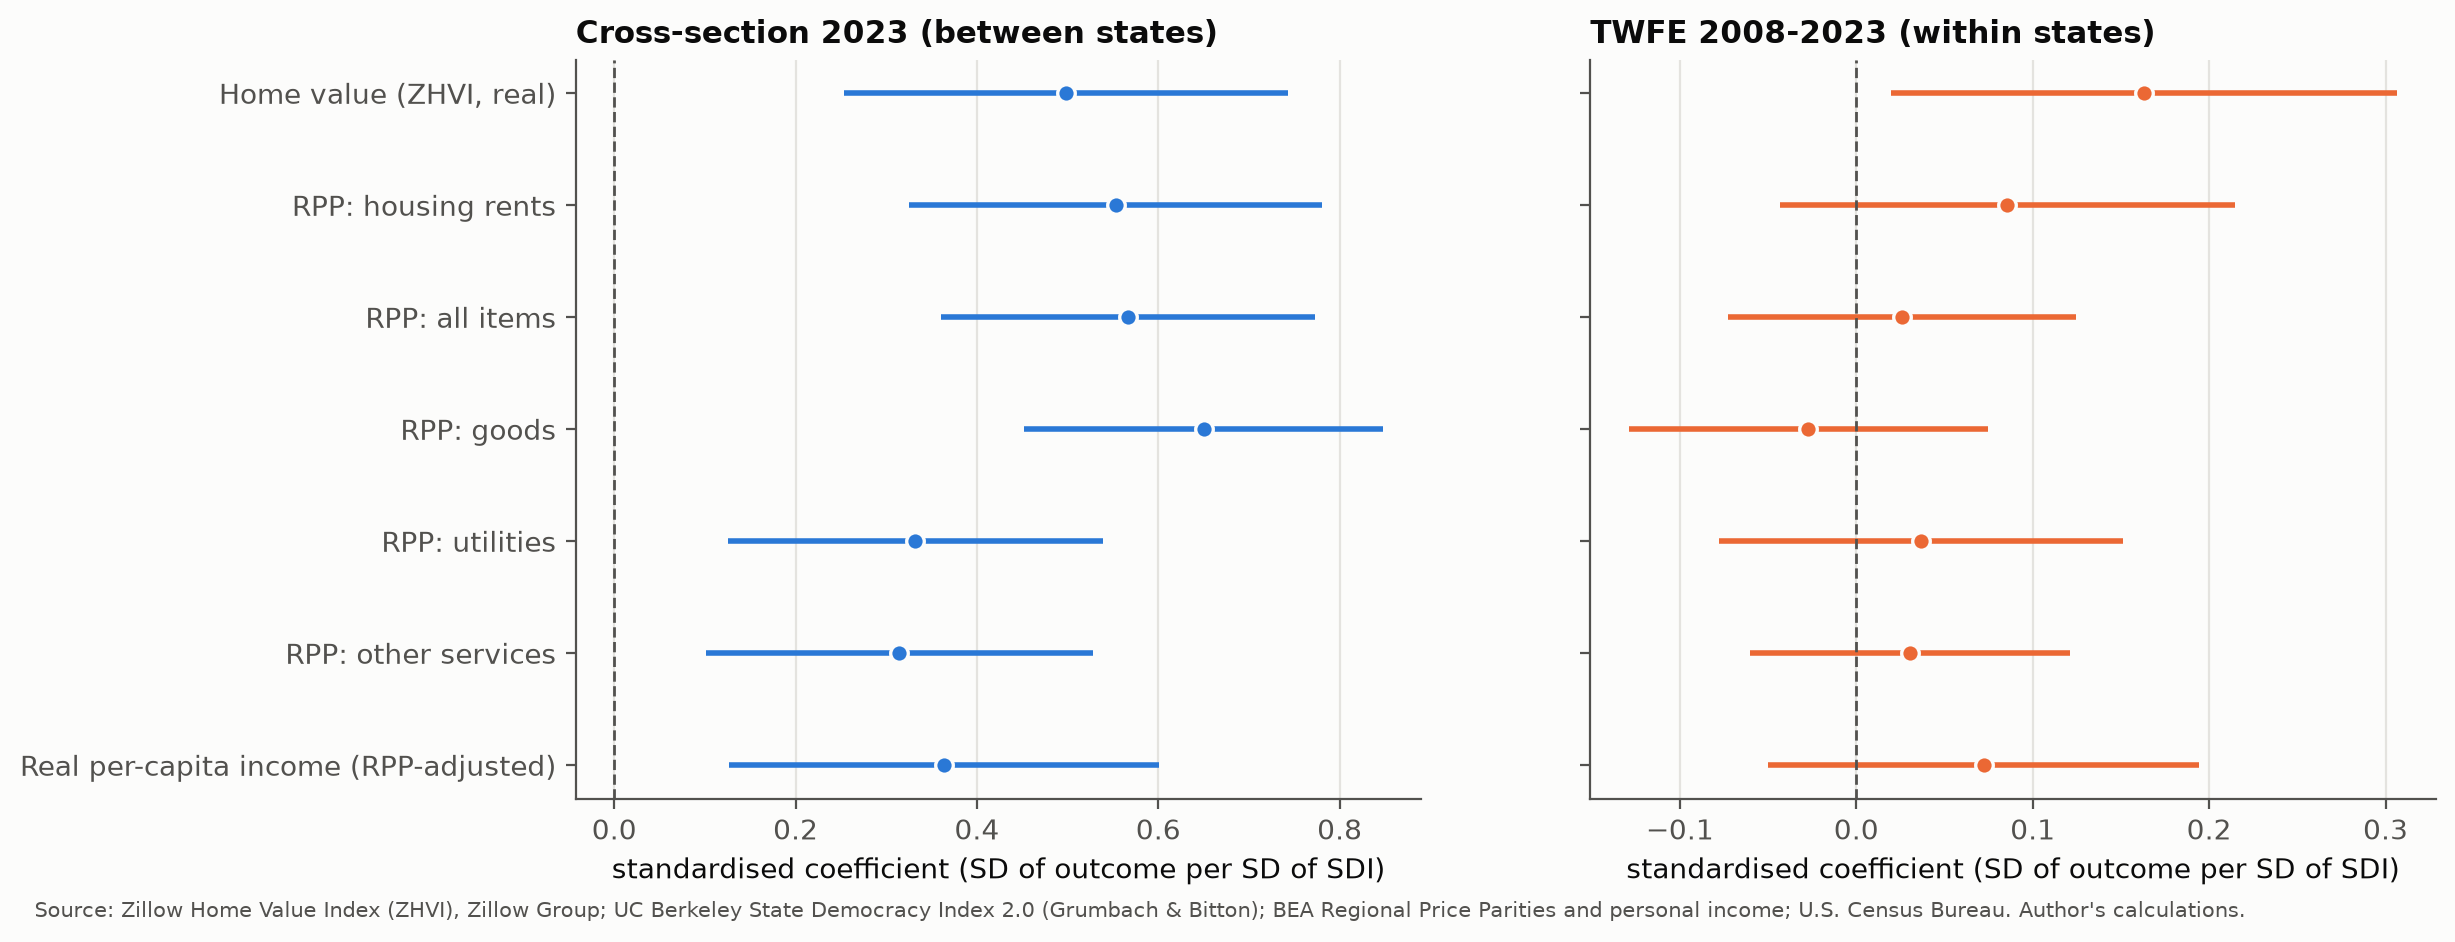

,outcome,spec,coef,se,ci_low,ci_high,p,pct,std_coef,std_ci_low,std_ci_high,n,r2,se_type
0,"Home value (ZHVI, real)",2023 bivariate,1.832e-01,0.046,0.093,0.273,6.425e-05,20.108,0.498,0.254,0.743,50,0.248,HC3
1,"Home value (ZHVI, real)","2023 + educ, urban",4.515e-02,0.044,-0.041,0.131,3.047e-01,4.618,0.123,-0.112,0.357,50,0.544,HC3
2,RPP: housing rents,2023 bivariate,1.473e-01,0.031,0.087,0.208,1.898e-06,15.873,0.553,0.326,0.781,50,0.306,HC3
3,RPP: housing rents,"2023 + educ, urban",3.111e-02,0.021,-0.010,0.072,1.384e-01,3.160,0.117,-0.038,0.271,50,0.799,HC3
4,RPP: all items,2023 bivariate,4.061e-02,0.008,0.026,0.055,7.161e-08,4.145,0.566,0.360,0.772,50,0.321,HC3
5,RPP: all items,"2023 + educ, urban",1.185e-02,0.007,-0.001,0.025,7.684e-02,1.192,0.165,-0.018,0.348,50,0.684,HC3
6,RPP: goods,2023 bivariate,2.564e-02,0.004,0.018,0.033,1.169e-10,2.597,0.650,0.452,0.848,50,0.422,HC3
7,RPP: goods,"2023 + educ, urban",1.671e-02,0.004,0.009,0.025,4.953e-05,1.685,0.424,0.219,0.628,50,0.537,HC3
8,RPP: utilities,2023 bivariate,8.197e-02,0.026,0.031,0.133,1.675e-03,8.542,0.332,0.125,0.539,50,0.110,HC3
9,RPP: utilities,"2023 + educ, urban",9.524e-03,0.036,-0.060,0.079,7.889e-01,0.957,0.039,-0.244,0.321,50,0.282,HC3


In [14]:
display(Image(str(FIG / 'f05_price_level_extension.png')))
res['prices']

Across states in 2023, SDI is about as strongly associated with the all-items and **goods** RPPs (standardised about 0.57-0.65) as with home values and rents (about 0.50-0.55). Utilities and other services are weaker (about 0.3). The pattern is not specific to housing; it is a general price-level gradient. With education and urban controls, the housing-rent and all-items associations shrink toward zero, while goods keeps a modest association. Within states over 2008-2023 (identical 799 state-year sample), only ZHVI shows a small positive coefficient, and RPP components are flat. RPP changes are relative to the U.S. level within a year, not state inflation rates. BEA's housing RPP is based on tenant rents only.

## 6. LGBTQ legal equality extension

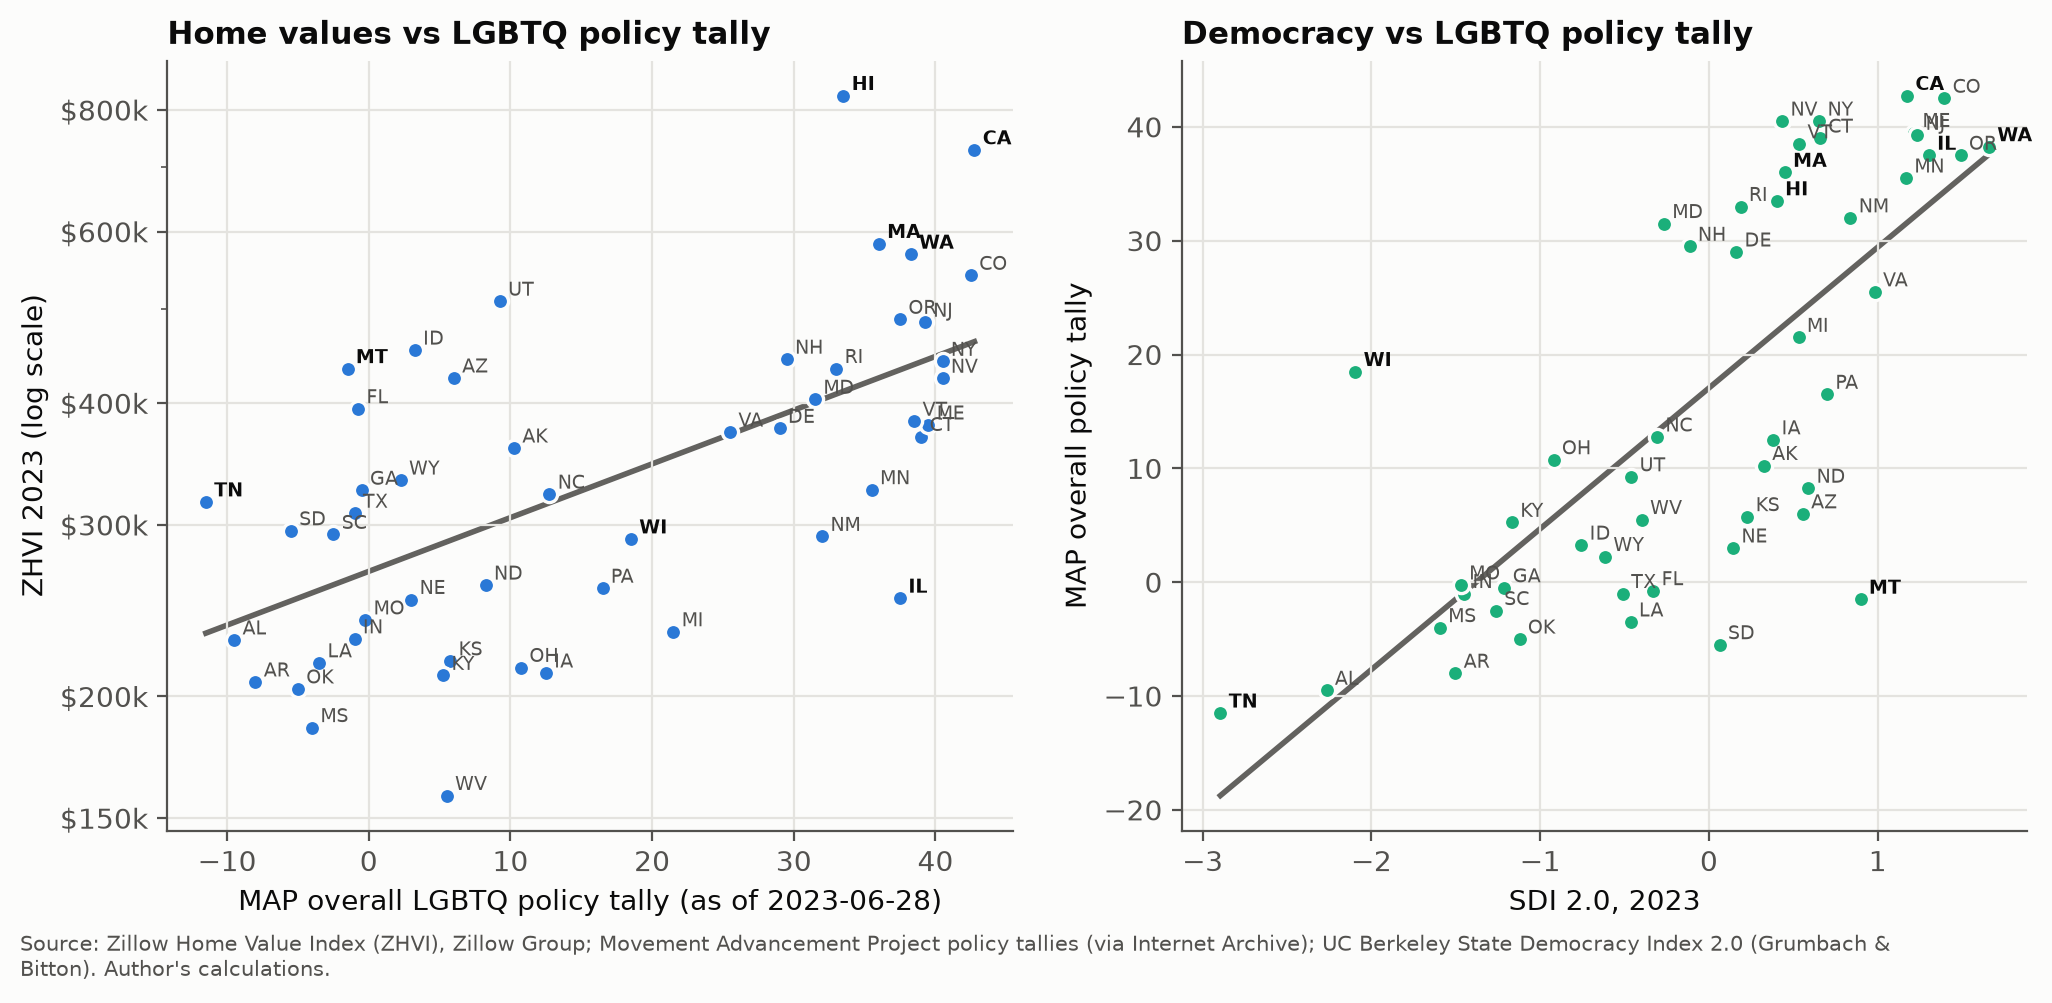

,pair,pearson_r,vif_bivariate
0,SDI vs MAP (2023),0.745,2.249


In [15]:
display(Image(str(FIG / 'f07_map_scatter.png')))
res['cross']['vif']

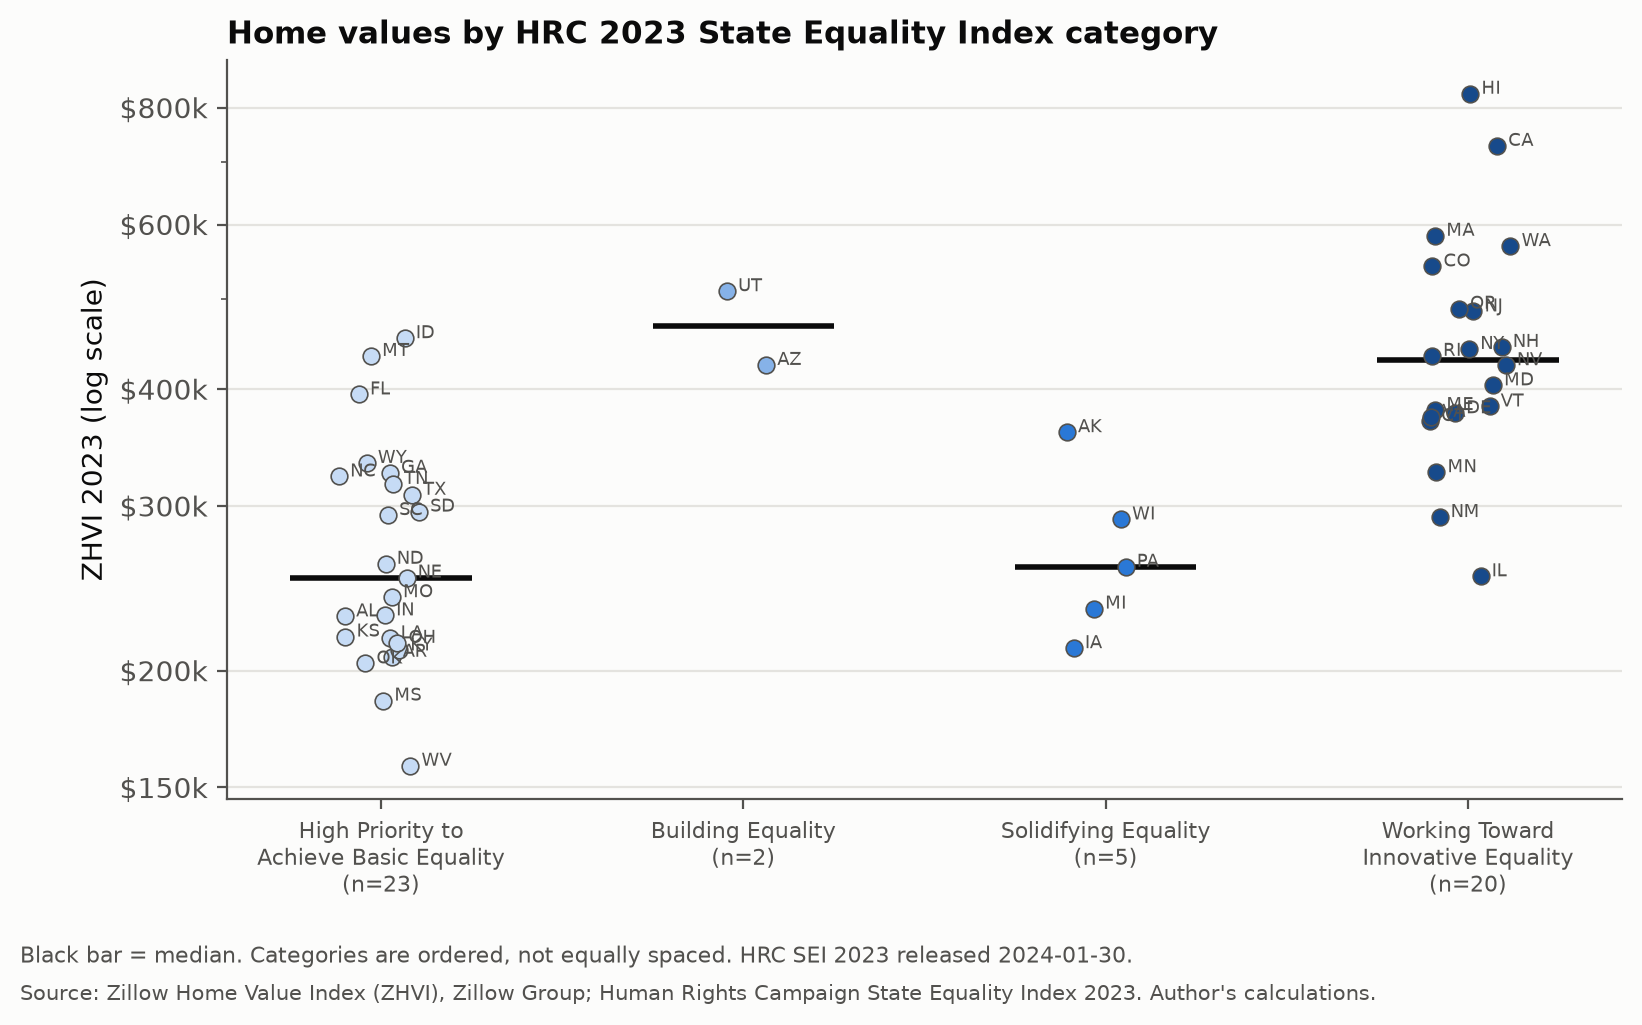

,model,category_vs_high_priority,n_in_category,coef,ci_low,ci_high,pct,n
0,HRC categories,Building Equality,2,0.566,0.289,0.842,76.093,50
1,HRC categories,Solidifying Equality,5,0.007,-0.225,0.239,0.707,50
2,HRC categories,Working Toward Innovative Equality,20,0.507,0.334,0.679,65.950,50
3,HRC categories + controls,Building Equality,2,0.142,-0.121,0.405,15.205,50
4,HRC categories + controls,Solidifying Equality,5,-0.187,-0.341,-0.033,-17.028,50
5,HRC categories + controls,Working Toward Innovative Equality,20,0.115,-0.083,0.314,12.217,50


In [16]:
display(Image(str(FIG / 'f06_hrc_categories.png')))
res['hrc']

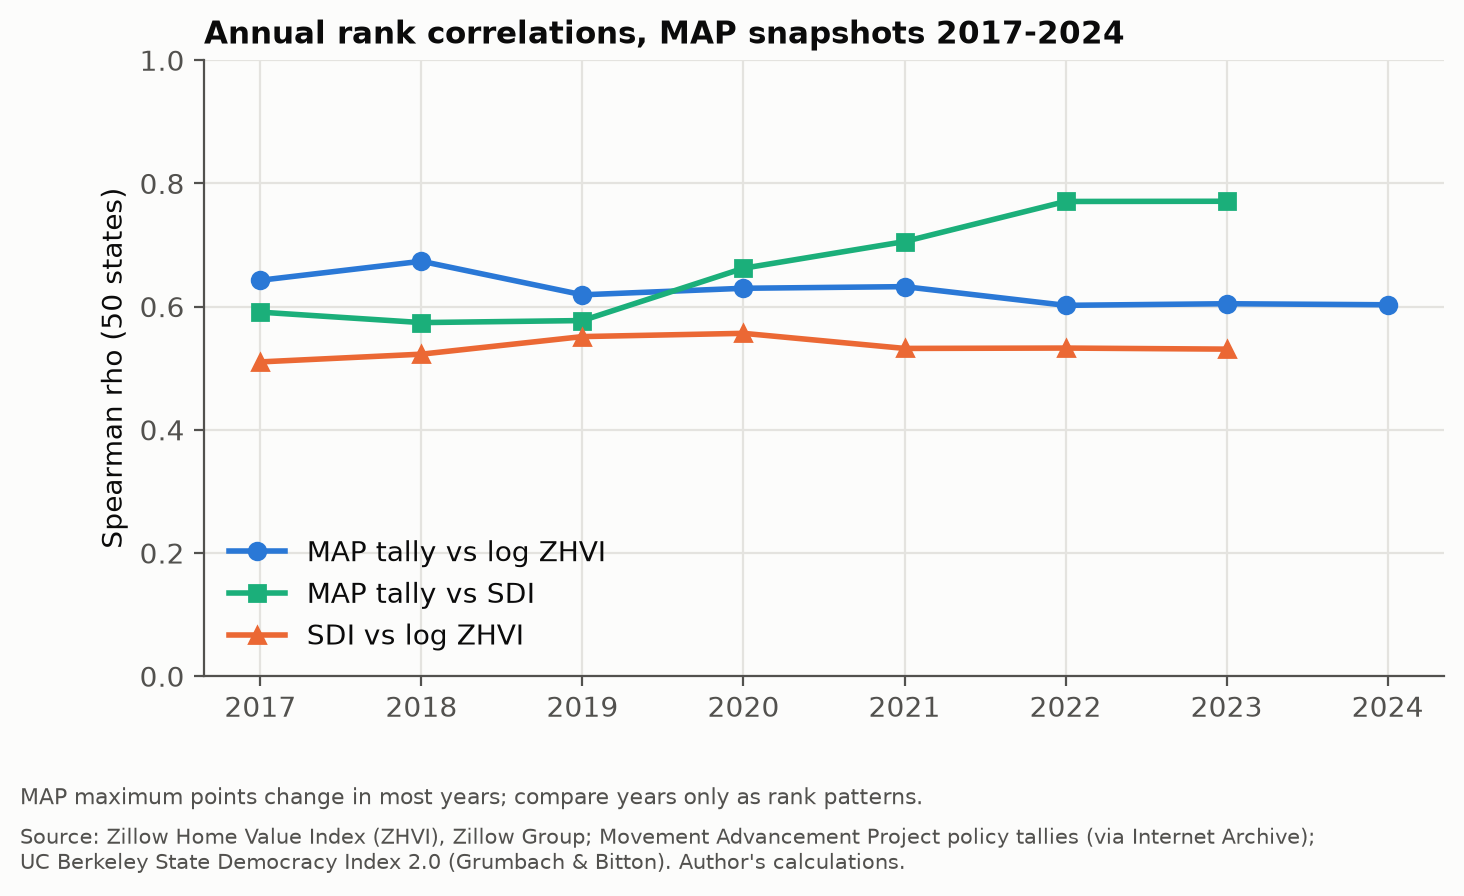

,year,map_asof,map_max_positive,n,spearman_map_logzhvi,spearman_map_sdi,spearman_sdi_logzhvi
0,2017,2017-07-07,40.0,50,0.643,0.591,0.510
1,2018,2018-06-21,37.0,50,0.674,0.574,0.523
2,2019,2019-06-26,40.5,50,0.619,0.577,0.551
3,2020,2020-07-01,38.5,50,0.630,0.662,0.557
4,2021,2021-06-30,38.5,50,0.632,0.706,0.532
5,2022,2022-07-01,42.5,50,0.602,0.771,0.533
6,2023,2023-06-28,43.5,50,0.605,0.771,0.531
7,2024,2024-06-27,44.5,50,0.603,NaN,NaN


In [17]:
display(Image(str(FIG / 'f09_map_annual.png')))
res['map_annual']

MAP's tally is somewhat *more* strongly associated with home values than SDI is (r about 0.61 vs 0.50). It shows the same collapse once income, education and urbanisation are controlled (E2). SDI and MAP are highly correlated (r = 0.75); together (E3), neither coefficient is distinguishable from zero. With 50 states the data cannot separate them. HRC categories tell the same story: the top category's median ZHVI is about $429k vs $252k in the lowest, and the gap shrinks substantially with controls. The "Building Equality" group has only two states (Utah, Arizona). The MAP-SDI rank correlation rose from 0.59 (2017) to 0.77 (2023). MAP's maximum attainable points changed in most years, so within-state changes in the tally are not interpreted.

## 7. A mover's-eye view (descriptive, 2023)

This section asks what the price gap costs a household that moves, not why the gap exists. Spec: `docs/analysis_plan.md`, "Mover's-eye extension" (written after the tercile summary had been seen, so not blind). *Origin* states rank in the bottom third on both SDI and the MAP tally; *destination* states rank in the top third on both. The mover keeps their origin income. Costs use the 2023 average 30-year rate, 10% down, and the state's effective property-tax rate; insurance and maintenance are excluded.

In [18]:
from hdl.mover import run_mover
mv = run_mover()  # writes data/processed/{entry_points,county_zhvi,mover_matrix}_2023.csv, t11-t14, f11-f12
print(f"2023 mean 30-year fixed rate: {mv['rate']:.2f}%")
print("origin states:", " ".join(mv['origins']))
print("destination states:", " ".join(mv['destinations']))
mv['origin_income']

2023 mean 30-year fixed rate: 6.81%
origin states: AL AR GA ID IN LA MO MS OK SC TN TX WY
destination states: CA CO CT IL ME MN NJ NM NY OR VT WA


p20        28679.0
p40        53580.0
median     67804.0
p60        84566.0
p80       132018.0
dtype: float64

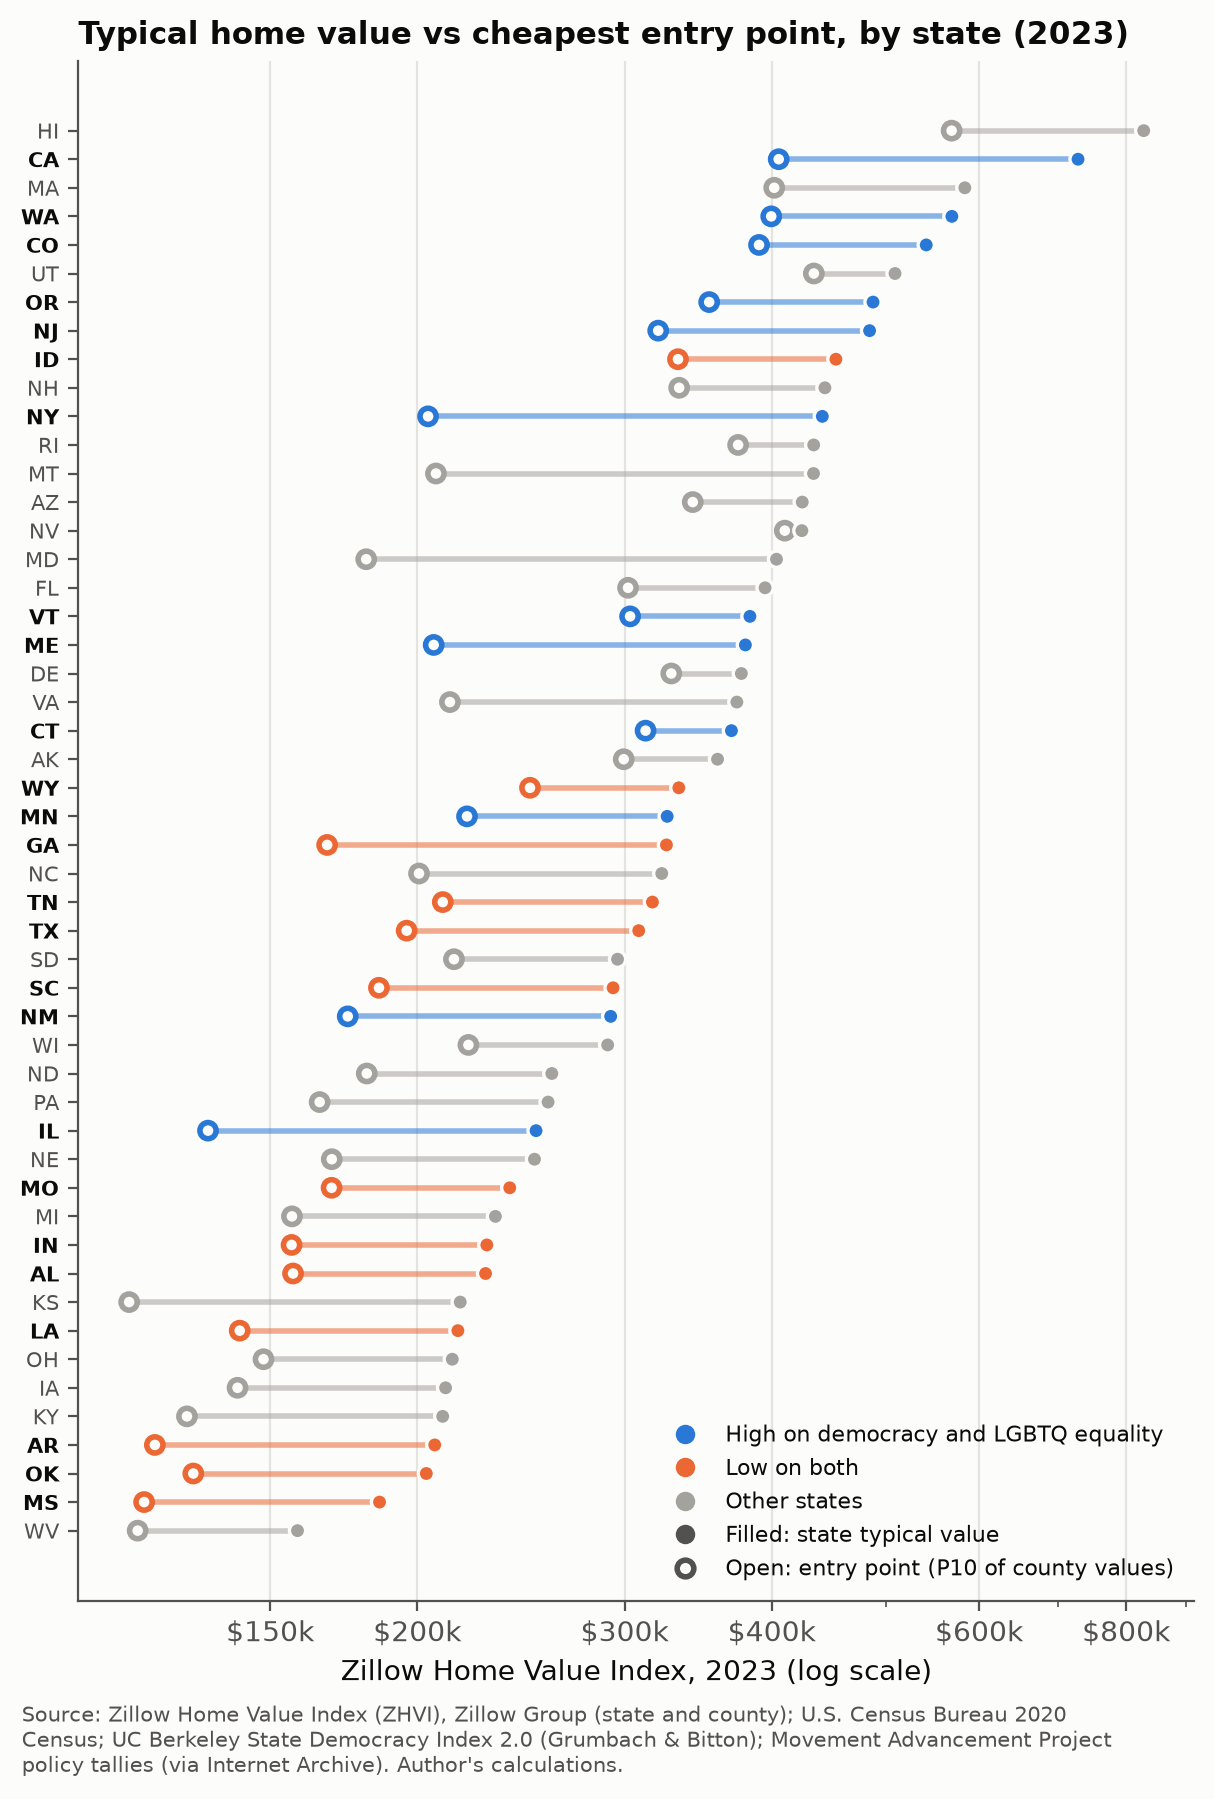

,measure,origin_median,destination_median,ratio,r_log_with_sdi,r_log_with_map,n
0,Home value: state typical (ZHVI),239646.000,412458.500,1.721,0.498,0.612,50
1,Home value: entry point E-P10,167687.776,307896.217,1.836,0.415,0.552,50
2,Home value: cheapest county >= 100k (E-100k),161177.168,271578.708,1.685,0.321,0.346,50
3,Home value: cheapest county (E-min),90672.774,167713.389,1.850,0.363,0.525,50
4,Median gross rent: state,1020.000,1472.000,1.443,0.475,0.631,50
5,Median gross rent: cheapest county >= 100k,929.000,1030.000,1.109,0.309,0.439,50


In [19]:
display(Image(str(FIG / 'f11_entry_points.png')))
mv['t13']

**Entry points.** E-P10 is the county home value below which the cheapest-county tenth of a state's residents live. It is 15-54% below the state typical value in destination states. But origin states have cheap counties too, so the destination/origin ratio barely moves (1.72 at state typical values, 1.84 at E-P10). Rents are different: the cheapest large-county rent in destination states is only about 11% above the origin median, versus 44% for state median rents. Small states with one large county (Vermont) make E-100k degenerate.

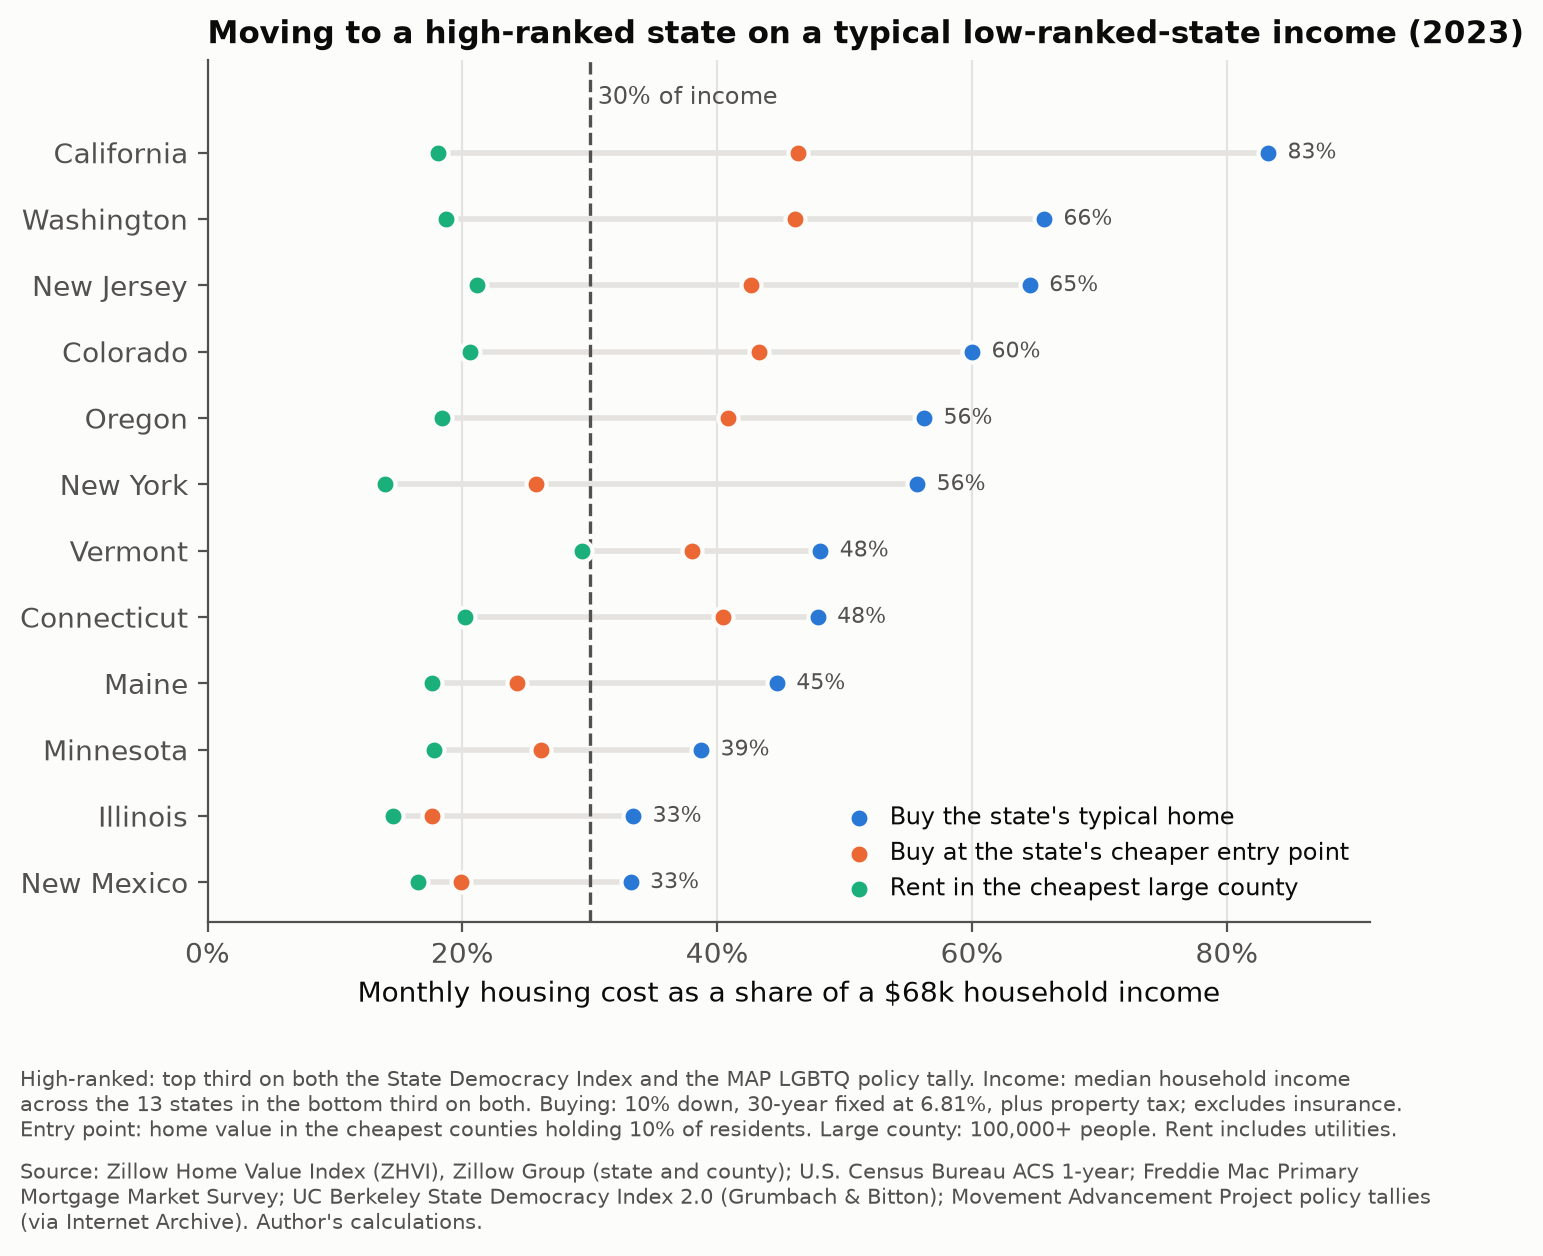

In [20]:
display(Image(str(FIG / 'f13_mover_cost_simple.png')))  # figure 2 in the published post

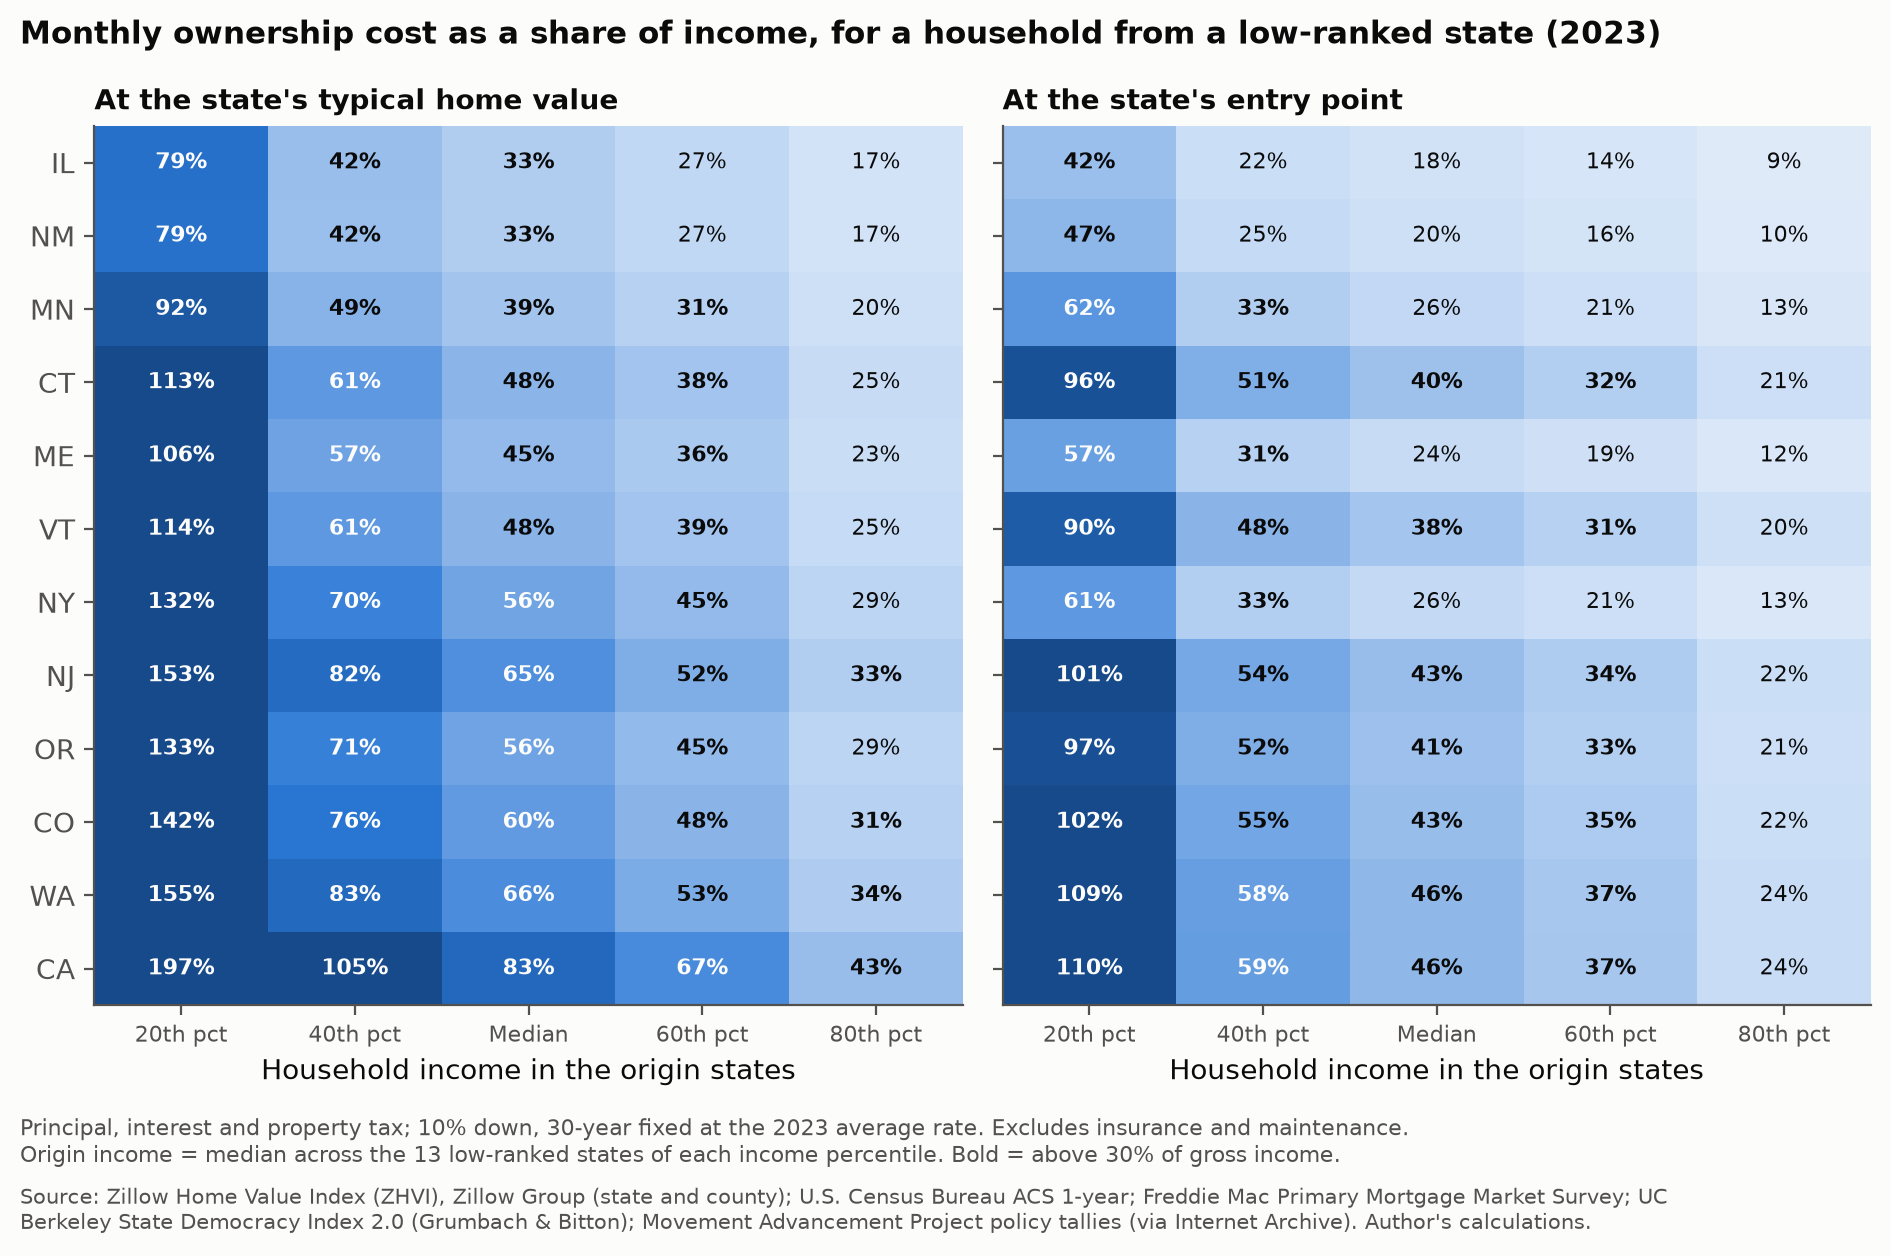

,origin_income_level,origin_income,owner_under30_median,owner_under30_p10,owner_under30_20down,rent_under30_median,rent_under30_entry,n_destinations
0,20th pct,28679.0,0,0,0,0,0,12
1,40th pct,53580.0,0,2,0,5,11,12
2,Median,67804.0,0,5,1,9,12,12
3,60th pct,84566.0,2,5,3,12,12,12
4,80th pct,132018.0,8,12,9,12,12,12


In [21]:
display(Image(str(FIG / 'f12_mover_cost_share.png')))
mv['t14']

In [22]:
mv['t12'][['dest','zhvi','entry_p10','pti_median','pti_p10','owner_share_median','owner_share_p10','rent_share_median','rent_share_entry','owner_share_local','down_median','down_p10']]

,dest,zhvi,entry_p10,pti_median,pti_p10,owner_share_median,owner_share_p10,rent_share_median,rent_share_entry,owner_share_local,down_median,down_p10
27,IL,252305,132838.459,3.721,1.959,0.334,0.176,0.219,0.145,0.282,25230.5,13283.846
31,NM,291946,174579.343,4.306,2.575,0.332,0.199,0.192,0.165,0.362,29194.6,17457.934
29,MN,326043,220442.322,4.809,3.251,0.387,0.262,0.224,0.178,0.309,32604.3,22044.232
26,CT,369703,312551.693,5.453,4.610,0.479,0.405,0.259,0.202,0.354,36970.3,31255.169
28,ME,379929,206528.303,5.603,3.046,0.447,0.243,0.210,0.176,0.411,37992.9,20652.830
34,VT,383312,303240.742,5.653,4.472,0.481,0.380,0.213,0.294,0.402,38331.2,30324.074
32,NY,441605,204273.152,6.513,3.013,0.557,0.258,0.276,0.140,0.460,44160.5,20427.315
30,NJ,484366,320390.746,7.144,4.725,0.645,0.427,0.295,0.212,0.439,48436.6,32039.075
33,OR,487648,353959.538,7.192,5.220,0.562,0.408,0.262,0.184,0.476,48764.8,35395.954
25,CO,541109,390199.128,7.980,5.755,0.600,0.433,0.313,0.206,0.438,54110.9,39019.913


In [23]:
mv['home']

,st,median,zhvi,rent,tax_rate,owner_share_home,rent_share_home
24,MS,54203,185780,898,0.007,0.265,0.199
35,OK,62138,203574,1020,0.008,0.256,0.197
2,AR,58700,206960,933,0.005,0.267,0.191
17,LA,58229,216540,1020,0.005,0.282,0.210
1,AL,62212,228579,982,0.004,0.272,0.189
14,IN,69477,229155,1044,0.007,0.256,0.180
23,MO,68545,239646,1019,0.008,0.275,0.178
39,SC,67804,293329,1170,0.005,0.324,0.207
42,TX,75780,308406,1413,0.014,0.345,0.224
41,TN,67631,316775,1214,0.005,0.352,0.215


**Reading the matrix.** A median-income household from the origin states (about $68k) would spend more than 30% of gross income on principal, interest and tax at the typical home in all 12 destinations, and over half of income in 6 of them. At entry points, 5 of 12 come in under 30% (IL, NM, ME, NY, MN). The same household at home pays about 28% at its own state's typical value (2023 rates make ownership tight everywhere). Renting is far more accessible: state median rent is under 30% in 9 of 12 destinations and the cheapest large-county rent in all 12. Households at the 20th percentile (about $29k) are over 30% everywhere on every measure. These are illustrative calculations under stated assumptions, not evidence that anyone was prevented from moving.

## Environment

In [24]:
import numpy, scipy, statsmodels, matplotlib
for m in (numpy, scipy, statsmodels, matplotlib, pd):
    print(m.__name__, m.__version__)
print(sys.version)

numpy 2.5.4
scipy 1.18.1
statsmodels 0.15.0
matplotlib 3.11.2
pandas 3.1.1
3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
